## The highway layer

A plain layer computes $y = H(x, W_H)$. A highway layer adds two gates:

$$
y = H(x, W_H) \odot T(x, W_T) + x \odot C(x, W_C),
\qquad C(x, W_C) = 1 - T(x, W_T).
$$

The paper uses a sigmoid transform gate,

$$
T(x) = \sigma(W_T^\top x + b_T),
$$

so every unit has its own gate value between 0 and 1. The layer therefore interpolates between two
behaviours:

$$
y =
\begin{cases}
x, & \text{if } T(x) = 0 \quad \text{(carry the input)},\\
H(x, W_H), & \text{if } T(x) = 1 \quad \text{(transform the input)}.
\end{cases}
$$

The same holds for the Jacobian. Consider one unit. Its output is

$$
y_i = T_i(x) H_i(x) + (1 - T_i(x)) x_i.
$$

If the gate is completely closed, $T_i(x)=0$, this becomes $y_i = x_i$. The layer is then exactly the
identity map, so its Jacobian is the identity matrix:

$$
\frac{\partial y_i}{\partial x_j} = \delta_{ij},
\qquad \frac{\partial y}{\partial x} = I.
$$

A gradient that arrives at the layer output is therefore multiplied by $I$ on the way back, so it
reaches the previous layer unchanged. This is the "information highway": a closed gate gives
gradients a direct path through the layer.

In a real sigmoid, $T_i(x)$ is never exactly zero and it depends on $x$. The exact Jacobian is

$$
J = \operatorname{diag}(T) H'(x) + \operatorname{diag}(1-T) + \operatorname{diag}(H(x)-x) T'(x),
$$

so the identity is the ideal, locally constant-gate case. Even when the last term is nonzero, the
carry term $\operatorname{diag}(1-T)$ keeps a direct gradient path, which is what makes very deep
highway networks easier to optimize.

For Equation (3) to work, $x$, $y$, $H(x)$ and $T(x)$ must have the same shape. This is why the
paper starts with a plain layer that changes the dimensionality and then stacks highway layers.

**The important initialization detail.** The bias $b_T$ starts at a negative value. The paper
recommends $-1$, $-2$ and $-3$ for depths around 10, 20 and 30; at depth 20 we use $-2$.
Since $\sigma(-2) \approx 0.12$, the gates start mostly closed and the deep network initially
behaves like a shallow one. Training then adapts the gates: they can open where the transform is
useful, or stay closed and become selective.

## Setup

In [60]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

torch 2.15.0+cu132 | CUDA available: True
NVIDIA GeForce RTX 3060 Ti


In [61]:
SEED = 0
DATA_ROOT = Path("data")
BATCH_SIZE = 128
EPOCHS = 25
LR = 0.1  # high CIFAR-10 rate; the highway shortcuts keep SGD stable
GATE_BIAS = -2.0
NUM_WORKERS = 2  # set to 0 on Windows if the data loader hangs


def set_seed(seed=SEED):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

## Data

CIFAR-10 has 50,000 training and 10,000 test images of size $32 \times 32$, in 10 classes.
Training images get random crops and horizontal flips, which approximate the paper's random
translations and mirroring. Both splits are normalized with the dataset mean and standard
deviation.

In [62]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_tf = transforms.Compose(
    [
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]
)
test_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_set = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=train_tf)
test_set = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=test_tf)
classes = test_set.classes

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=device.type == "cuda",
)
test_loader = DataLoader(
    test_set,
    batch_size=512,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=device.type == "cuda",
)

# A fixed batch used later to inspect the gates.
probe_iter = iter(test_loader)  # keep the iterator alive for a clean worker shutdown
probe_x, _ = next(probe_iter)
probe_x = probe_x[:256].to(device)

print(f"{len(train_set):,} train / {len(test_set):,} test images")

50,000 train / 10,000 test images


## The highway layer in code

The code is a direct translation of Equation (3) in its convolutional form. One 3×3 convolution
produces `H`, another produces the gate logits, and the sigmoid turns those into `T`. Both use
padding 1, so the output keeps the same shape as the input. The full gate tensor is stored so we
can inspect it after training.

In [63]:
class Highway(nn.Module):
    def __init__(self, channels: int, gate_bias: float = GATE_BIAS):
        super().__init__()
        self.H = nn.Conv2d(channels, channels, 3, padding=1)
        self.gate = nn.Conv2d(channels, channels, 3, padding=1)
        assert self.gate.bias is not None
        nn.init.constant_(self.gate.bias, gate_bias)  # start biased towards carry
        self.last_gate = torch.zeros(1)  # filled on every forward pass
        self.gate_off = False  # used later to switch this layer off

    def forward(self, x):
        h = F.relu(self.H(x))
        t = torch.sigmoid(self.gate(x))
        if self.gate_off:
            t = torch.zeros_like(t)
        self.last_gate = t.detach()
        return h * t + x * (1 - t)

## The convolutional highway network

The model is a compact convolutional highway network inspired by the paper's CIFAR-10 setup:

* a plain 3×3 convolutional stem,
* two plain strided convolutions that halve the spatial size and change channels,
* nineteen highway blocks split 6/6/7 over three stages,
* global average pooling and a linear classifier.

Counting the stem, this is a depth-20 hidden stack: one plain layer followed by 19 highway
layers. The paper's released 19-layer CIFAR-10 network is different: it interleaves 14 highway
layers with plain convolutions. This notebook uses 19 highway blocks to study a deeper gated
stack. The stage widths are 32, 64, and 128.

`H` and `T` are both 3×3 convolutions with padding 1. They preserve channels and spatial size, so
the carry connection is valid everywhere. Layers that change channels or resolution stay plain, as
in Section 2.1 of the paper.

This is a compact variant of the paper's convolutional setup, not an exact FitNet reproduction.
All weights use He initialization. The transform-gate biases are reset to `-2` after
initialization, so the gates start mostly closed.

In [64]:
class Net(nn.Module):
    def __init__(
        self,
        channels: tuple[int, int, int] = (32, 64, 128),
        blocks_per_stage: tuple[int, int, int] = (6, 6, 7),
    ):
        super().__init__()
        c1, c2, c3 = channels
        self.stem = nn.Sequential(
            nn.Conv2d(3, c1, 3, padding=1),
            nn.ReLU(),
        )
        self.blocks = nn.ModuleList(
            Highway(ch) for ch, n in zip(channels, blocks_per_stage, strict=True) for _ in range(n)
        )
        self.break1 = blocks_per_stage[0]
        self.break2 = blocks_per_stage[0] + blocks_per_stage[1]
        self.down1 = nn.Sequential(
            nn.Conv2d(c1, c2, 3, stride=2, padding=1),
            nn.ReLU(),
        )
        self.down2 = nn.Sequential(
            nn.Conv2d(c2, c3, 3, stride=2, padding=1),
            nn.ReLU(),
        )
        self.head = nn.Linear(c3, 10)

    def forward(self, x):
        x = self.stem(x)
        for i, block in enumerate(self.blocks):
            if i == self.break1:
                x = self.down1(x)
            if i == self.break2:
                x = self.down2(x)
            x = block(x)
        x = x.mean(dim=(2, 3))  # global average pooling
        return self.head(x)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def init_weights(model):
    """He initialization for every conv and linear layer, then reset the gate biases."""
    for module in model.modules():
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            nn.init.kaiming_normal_(module.weight, nonlinearity="relu")
            if module.bias is not None:
                nn.init.zeros_(module.bias)
    for module in model.modules():
        if isinstance(module, Highway):
            assert module.gate.bias is not None
            nn.init.constant_(module.gate.bias, GATE_BIAS)

## Training

The setup is paper-inspired, not an exact reproduction of the authors' released Caffe config:

* SGD with momentum 0.9,
* batch size 128,
* He initialization for all weights,
* weight decay 5e-4,
* exponential learning-rate decay by a factor of 0.89 per epoch,
* 25 epochs.

The paper selected its learning rate, momentum, and decay with a random search. The authors'
released 19-layer CIFAR-10 config (`examples/highways/cifar10-19layers` in their Caffe code)
trains for 200k iterations (about 400 epochs at batch 100) with Nesterov momentum, base learning
rate 0.025, step decay, weight decay 1e-3 and dropout 0.2. This notebook uses a much shorter
run and a simpler schedule, so its accuracy is expected to be below the paper's Table 2 number.

We also clip the gradient norm at 10. The paper does not mention clipping, but it keeps SGD stable.

The model's mean gate values are recorded after every epoch.

In [65]:
@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(dim=1) == y).sum().item()
        total += y.numel()
    return correct / total


@torch.no_grad()
def gate_means_on_batch(model, x):
    model.eval()
    model(x)
    return [block.last_gate.mean().item() for block in model.blocks]


def train(model, track_gates: bool = False, epochs: int = EPOCHS, lr: float = LR):
    model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=0.89)
    loss_fn = nn.CrossEntropyLoss()

    history = {"loss": [], "acc": [], "gates": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(x), y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
            opt.step()
            running += loss.item() * y.numel()
        history["loss"].append(running / len(train_set))
        history["acc"].append(accuracy(model, test_loader))
        if track_gates:
            history["gates"].append(gate_means_on_batch(model, probe_x))
        print(
            f"epoch {epoch:3d}/{epochs} | lr {opt.param_groups[0]['lr']:.4f} "
            f"| loss {history['loss'][-1]:.3f} | test acc {history['acc'][-1]:.1%}"
        )
        sched.step()

    print(f"trained in {time.time() - start:.1f}s")
    return history

## Train the highway network

In [66]:
set_seed()
highway = Net()
init_weights(highway)
print(f"{n_params(highway):,} parameters")
highway_hist = train(highway, track_gates=True)

2,714,826 parameters
epoch   1/25 | lr 0.1000 | loss 1.882 | test acc 37.7%
epoch   2/25 | lr 0.0890 | loss 1.520 | test acc 45.9%
epoch   3/25 | lr 0.0792 | loss 1.299 | test acc 55.1%
epoch   4/25 | lr 0.0705 | loss 1.103 | test acc 62.3%
epoch   5/25 | lr 0.0627 | loss 0.954 | test acc 69.0%
epoch   6/25 | lr 0.0558 | loss 0.829 | test acc 72.5%
epoch   7/25 | lr 0.0497 | loss 0.740 | test acc 73.3%
epoch   8/25 | lr 0.0442 | loss 0.660 | test acc 76.7%
epoch   9/25 | lr 0.0394 | loss 0.607 | test acc 78.2%
epoch  10/25 | lr 0.0350 | loss 0.554 | test acc 77.6%
epoch  11/25 | lr 0.0312 | loss 0.518 | test acc 79.8%
epoch  12/25 | lr 0.0278 | loss 0.478 | test acc 80.8%
epoch  13/25 | lr 0.0247 | loss 0.444 | test acc 82.9%
epoch  14/25 | lr 0.0220 | loss 0.420 | test acc 83.0%
epoch  15/25 | lr 0.0196 | loss 0.383 | test acc 83.7%
epoch  16/25 | lr 0.0174 | loss 0.368 | test acc 84.4%
epoch  17/25 | lr 0.0155 | loss 0.342 | test acc 85.5%
epoch  18/25 | lr 0.0138 | loss 0.314 | test

## Results

Training curves for the highway model. There is no plain baseline in this notebook, so this is
not the paper's depth comparison.

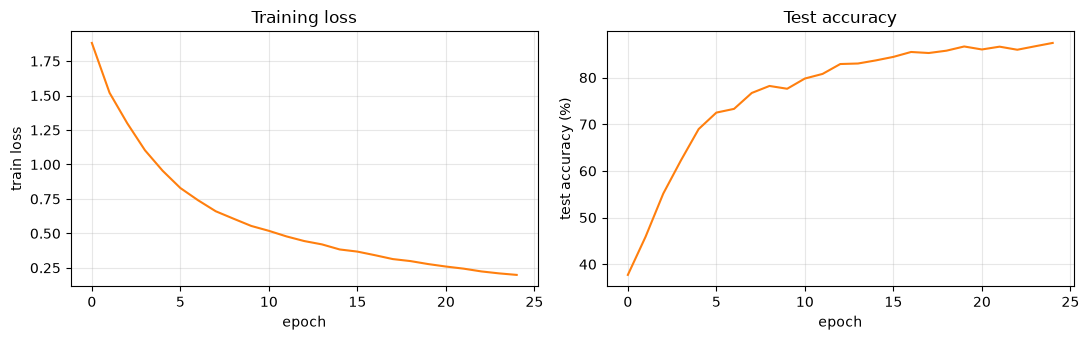

final test accuracy: 87.4%


In [67]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.5))

ax_loss.plot(highway_hist["loss"], color="tab:orange")
ax_acc.plot([100 * a for a in highway_hist["acc"]], color="tab:orange")

ax_loss.set(xlabel="epoch", ylabel="train loss", title="Training loss")
ax_acc.set(xlabel="epoch", ylabel="test accuracy (%)", title="Test accuracy")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"final test accuracy: {highway_hist['acc'][-1]:.1%}")

## Gradient flow through depth

Backpropagation multiplies one Jacobian per layer. Without a shortcut, those products can shrink
the gradient as depth grows. A highway layer has a shortcut: when $T(x)=0$ its Jacobian is the
identity, so the gradient can travel through it unchanged.

Below we compare the gradient that arrives at each block input at initialization and after training.

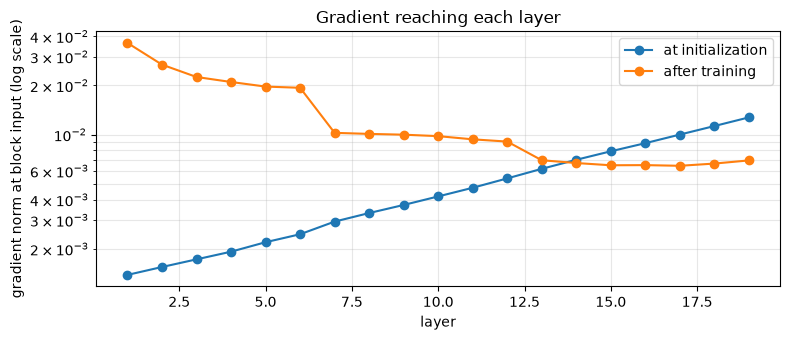

In [68]:
def layer_input_grad_norms(model, x, y):
    model.train()
    model.zero_grad(set_to_none=True)

    h = model.stem(x)
    hs = []
    for i, block in enumerate(model.blocks):
        if i == model.break1:
            h = model.down1(h)
        if i == model.break2:
            h = model.down2(h)
        h.retain_grad()
        hs.append(h)
        h = block(h)

    loss = F.cross_entropy(model.head(h.mean(dim=(2, 3))), y)
    loss.backward()

    norms = [max(t.grad.norm().item(), 1e-12) for t in hs]
    model.zero_grad(set_to_none=True)
    return norms


set_seed()
fresh_highway = Net().to(device)
init_weights(fresh_highway)  # match the initialization used for the trained model

x_grad, y_grad = next(iter(train_loader))
x_grad, y_grad = x_grad[:256].to(device), y_grad[:256].to(device)

fig, ax = plt.subplots(figsize=(8, 3.5))
layers = range(1, len(highway.blocks) + 1)
ax.semilogy(
    layers,
    layer_input_grad_norms(fresh_highway, x_grad, y_grad),
    "o-",
    label="at initialization",
)
ax.semilogy(
    layers,
    layer_input_grad_norms(highway, x_grad, y_grad),
    "o-",
    label="after training",
)
highway.eval()
ax.set(
    xlabel="layer",
    ylabel="gradient norm at block input (log scale)",
    title="Gradient reaching each layer",
)
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

## Gate bias and gate activity per layer

The paper's Figure 2 inspects the learned transform-gate biases and the mean gate activity for
50-layer fully connected networks on MNIST and CIFAR-100. We repeat the same measurements for
this convolutional CIFAR-10 model. A negative bias does not necessarily mean that a layer is
switched off. It often makes the gates more selective: some units stay closed while others open
for particular inputs.

The bars show the average gate value of each layer over the whole test set.

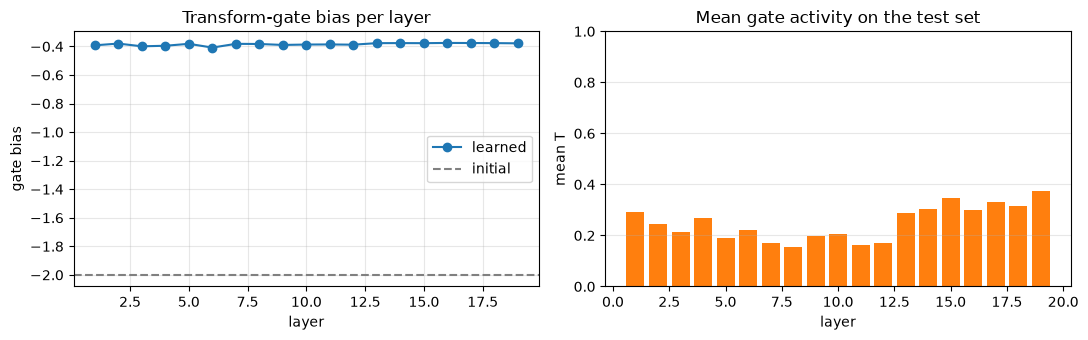

In [69]:
def gate_biases(model):
    return [block.gate.bias.mean().item() for block in model.blocks]


@torch.no_grad()
def gate_activity(model, loader):
    model.eval()
    sums = torch.zeros(len(classes), len(model.blocks))
    counts = torch.zeros(len(classes))
    for x, y in loader:
        model(x.to(device))
        batch_means = torch.stack(
            [block.last_gate.mean(dim=(1, 2, 3)).cpu() for block in model.blocks],
            dim=1,
        )
        for c in range(len(classes)):
            mask = y == c
            sums[c] += batch_means[mask].sum(dim=0)
            counts[c] += mask.sum()
    return sums.sum(dim=0) / counts.sum(), sums / counts[:, None]


overall_activity, class_activity = gate_activity(highway, test_loader)
biases = gate_biases(highway)

fig, (ax_bias, ax_act) = plt.subplots(1, 2, figsize=(11, 3.5))
ax_bias.plot(range(1, len(highway.blocks) + 1), biases, "o-", label="learned")
ax_bias.axhline(GATE_BIAS, color="gray", linestyle="--", label="initial")
ax_bias.set(xlabel="layer", ylabel="gate bias", title="Transform-gate bias per layer")
ax_bias.legend()
ax_bias.grid(alpha=0.3)

ax_act.bar(range(1, len(highway.blocks) + 1), overall_activity, color="tab:orange")
ax_act.set(
    xlabel="layer",
    ylabel="mean T",
    title="Mean gate activity on the test set",
    ylim=(0, 1),
)
ax_act.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

## How the gates change during training

Each row is one highway layer and each column is an epoch. Bright cells mean the layer transforms
its input ($T$ close to 1); dark cells mean it mostly carries the input forward ($T$ close to 0).
At initialization the gates are near $\sigma(-2) \approx 0.12$. The first column is already
after one epoch, and the gates keep moving. In this compact run they open on average. The
paper's much deeper networks often moved their biases further negative and stayed selective;
here the model uses the transform path more, and 25 epochs is a short run.

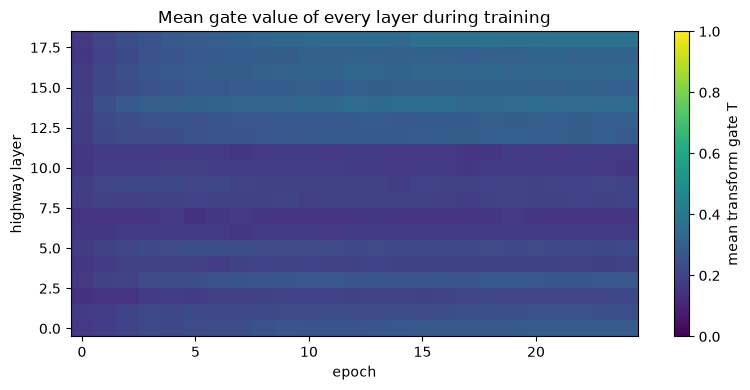

In [70]:
gate_history = torch.tensor(highway_hist["gates"]).T  # layers x epochs

plt.figure(figsize=(8, 4))
plt.imshow(gate_history, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=1)
plt.colorbar(label="mean transform gate T")
plt.xlabel("epoch")
plt.ylabel("highway layer")
plt.title("Mean gate value of every layer during training")
plt.tight_layout()
plt.show()

## What a single image does to the gates

In a convolutional highway layer the gate is a tensor with one value per channel and spatial
position. The left panel shows the gate map of one layer, averaged over channels, for a single test
image. The right panel shows the distribution of all gate values in that layer. Many values are
strongly closed or strongly open, so the layer is selective rather than applying one global
transformation.

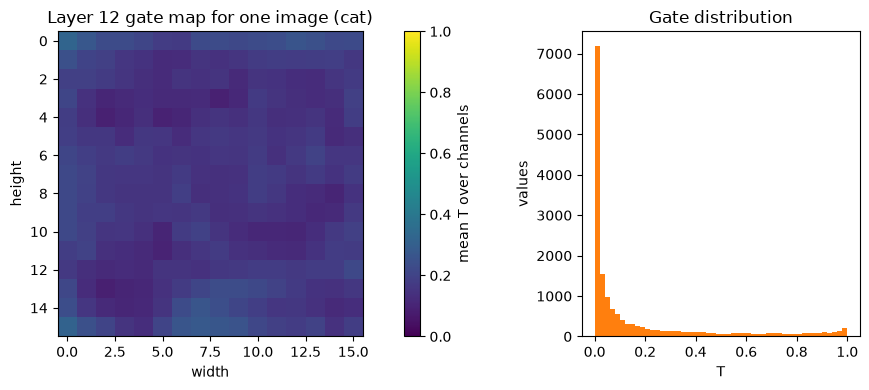

In [71]:
image, label = test_set[0]
with torch.no_grad():
    highway(image.unsqueeze(0).to(device))

layer = highway.break2 - 1  # last block of stage two, 16x16 gates
block = highway.blocks[layer]
assert isinstance(block, Highway)
gate_map = block.last_gate[0].mean(dim=0).cpu()  # average over channels
gates = block.last_gate.cpu()

fig, (ax_map, ax_hist) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
im = ax_map.imshow(gate_map, cmap="viridis", vmin=0, vmax=1)
ax_map.set(
    xlabel="width",
    ylabel="height",
    title=f"Layer {layer + 1} gate map for one image ({classes[label]})",
)
fig.colorbar(im, ax=ax_map, label="mean T over channels")

ax_hist.hist(gates.flatten(), bins=50, range=(0, 1), color="tab:orange")
ax_hist.set(xlabel="T", ylabel="values", title="Gate distribution")
plt.tight_layout()
plt.show()

## Class-specific routing

The gates can route different inputs differently. The paper's Figure 3 compares the mean gate
activity of each class with the overall average for its 50-layer networks. We repeat the
measurement for this CIFAR-10 model. Red cells mean that a class transforms more than
usual in that layer; blue cells mean it carries more than usual.

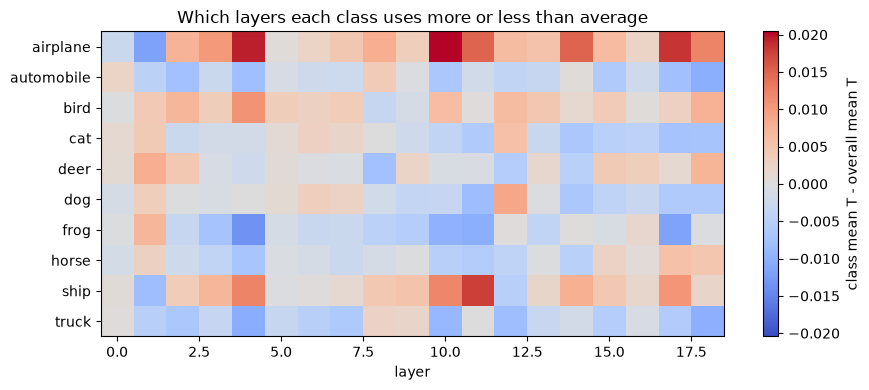

In [72]:
diff = (class_activity - overall_activity).numpy()
limit = max(abs(diff).max(), 0.01)

plt.figure(figsize=(9, 4))
plt.imshow(diff, aspect="auto", cmap="coolwarm", vmin=-limit, vmax=limit)
plt.colorbar(label="class mean T - overall mean T")
plt.yticks(range(len(classes)), classes)
plt.xlabel("layer")
plt.title("Which layers each class uses more or less than average")
plt.tight_layout()
plt.show()

## The information highway

A highway layer can pass its input through almost unchanged. The plot below measures how similar
each layer's output is to its input using cosine similarity. Values close to 1 mean the layer
copied its input; values near 0 mean it changed the representation substantially.

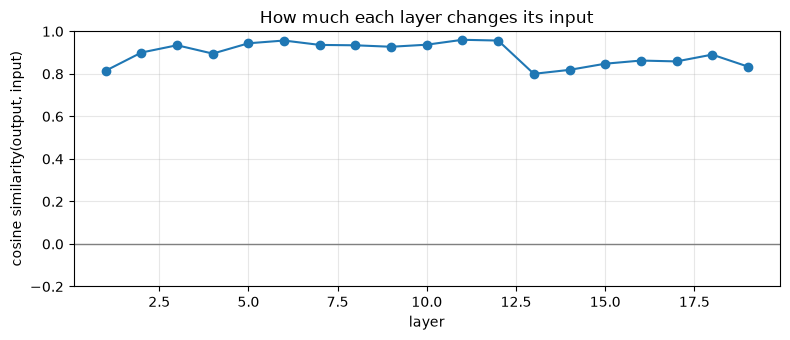

In [73]:
@torch.no_grad()
def layer_similarity(model, x):
    model.eval()
    h = model.stem(x)
    sims = []
    for i, block in enumerate(model.blocks):
        if i == model.break1:
            h = model.down1(h)
        if i == model.break2:
            h = model.down2(h)
        h_new = block(h)
        sims.append(F.cosine_similarity(h_new, h, dim=1).mean().item())
        h = h_new
    return sims


plt.figure(figsize=(8, 3.5))
plt.plot(range(1, len(highway.blocks) + 1), layer_similarity(highway, probe_x), "o-")
plt.axhline(0, color="gray", linewidth=1)
plt.ylim(-0.2, 1)
plt.xlabel("layer")
plt.ylabel("cosine similarity(output, input)")
plt.title("How much each layer changes its input")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Lesioning layers

The paper's Figure 4 asks how much each layer actually contributes in its 50-layer networks. We
close all transform gates of one layer at a time, which forces that layer to copy its input, and
measure how far test accuracy drops. A drop near zero means the layer is barely used; a large
drop means the layer is important.

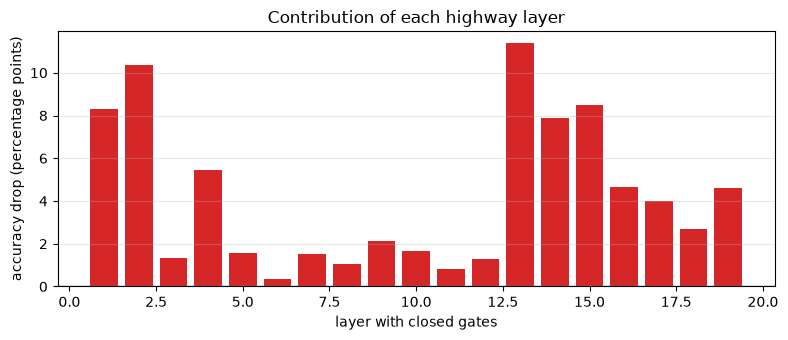

In [74]:
baseline_acc = accuracy(highway, test_loader)
drops = []
for block in highway.blocks:
    assert isinstance(block, Highway)
    block.gate_off = True
    drops.append(100 * (baseline_acc - accuracy(highway, test_loader)))
    block.gate_off = False

plt.figure(figsize=(8, 3.5))
plt.bar(range(1, len(highway.blocks) + 1), drops, color="tab:red")
plt.axhline(0, color="gray", linewidth=1)
plt.xlabel("layer with closed gates")
plt.ylabel("accuracy drop (percentage points)")
plt.title("Contribution of each highway layer")
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## Feature space

The global average pooled feature before the classifier is the network's learned representation. A
t-SNE plot compresses that 128-dimensional space to two dimensions. Well-separated clusters mean the
representation has become easier to classify. t-SNE is qualitative, but it is a useful picture of
what the gated depth does to the features.

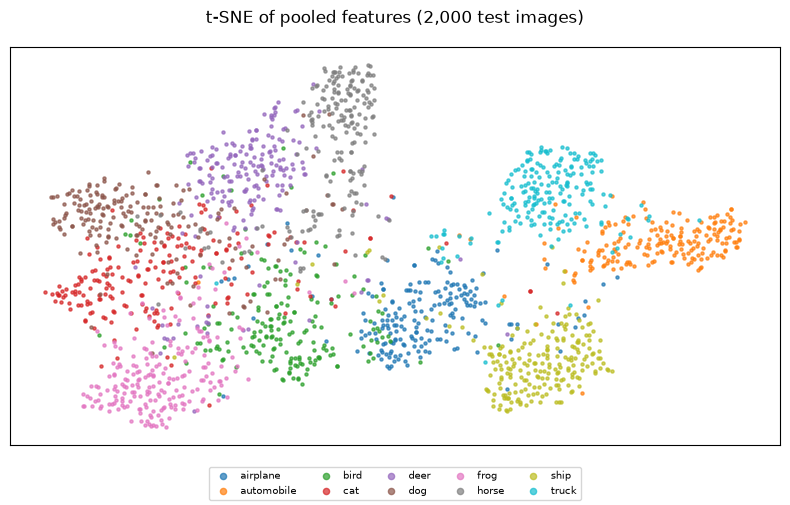

In [75]:
@torch.no_grad()
def penultimate_features(model, loader, limit=2000):
    model.eval()
    feats, labels = [], []
    seen = 0
    for x, y in loader:
        h = model.stem(x.to(device))
        for i, block in enumerate(model.blocks):
            if i == model.break1:
                h = model.down1(h)
            if i == model.break2:
                h = model.down2(h)
            h = block(h)
        h = h.mean(dim=(2, 3))  # global average pooling
        feats.append(h.cpu())
        labels.append(y)
        seen += y.numel()
        if seen >= limit:
            break
    return torch.cat(feats)[:limit].numpy(), torch.cat(labels)[:limit].numpy()


def tsne_2d(feats):
    return TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(feats)


feats_highway, labels_highway = penultimate_features(highway, test_loader)
emb_highway = tsne_2d(feats_highway)

fig, ax = plt.subplots(figsize=(8, 5))
for c, name in enumerate(classes):
    mask = labels_highway == c
    ax.scatter(emb_highway[mask, 0], emb_highway[mask, 1], s=5, alpha=0.7, label=name)
ax.set(xticks=[], yticks=[])

handles, names = ax.get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=5, fontsize=7, markerscale=2)
plt.suptitle("t-SNE of pooled features (2,000 test images)")
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

## A look at predictions

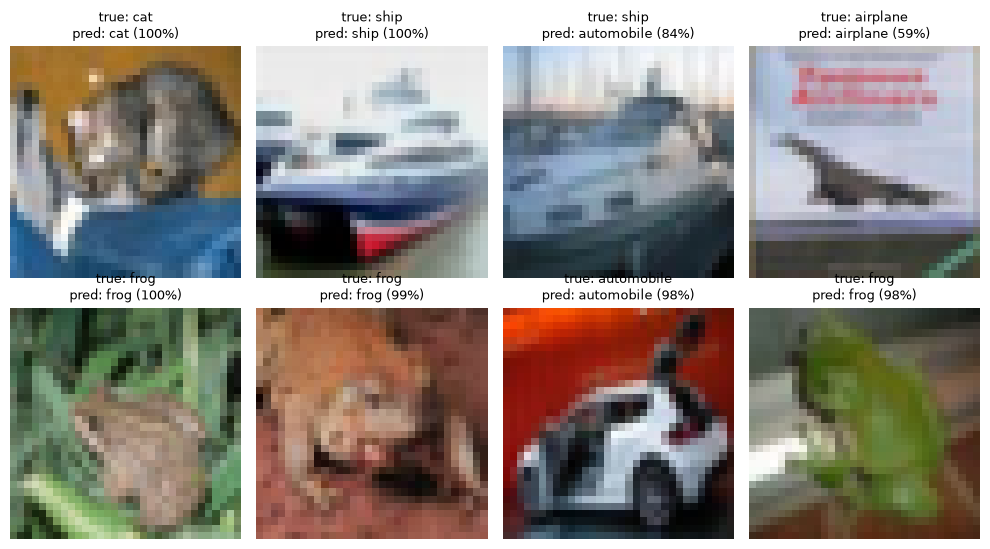

In [76]:
sample_iter = iter(test_loader)  # keep the iterator alive for a clean worker shutdown
images, labels = next(sample_iter)
images, labels = images[:8], labels[:8]  # one batch holds 512, show 8
with torch.no_grad():
    probs = highway(images.to(device)).softmax(dim=1).cpu()
labels = labels.tolist()
preds = probs.argmax(dim=1).tolist()
confs = probs.max(dim=1).values.tolist()

fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for ax, img, label, pred, conf in zip(axes.flat, images, labels, preds, confs, strict=True):
    rgb = (img * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1)
    ax.imshow(rgb.permute(1, 2, 0))
    ax.set_title(f"true: {classes[label]}\npred: {classes[pred]} ({conf:.0%})", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()